<a href="https://colab.research.google.com/github/eyramg/A04-clustering/blob/main/Copy_of_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

In [6]:

import numpy as np
import pandas as pd

def createData(noise, N=50):
    np.random.seed(100)

    X1 = np.array([
        np.random.normal(1, noise, N),
        np.random.normal(1, noise, N)
    ])

    X2 = np.array([
        np.random.normal(3, noise, N),
        np.random.normal(2, noise, N)
    ])

    X3 = np.array([
        np.random.normal(5, noise, N),
        np.random.normal(3, noise, N)
    ])

    gdf1 = pd.DataFrame({
        'x1': X1[0, :],
        'x2': X1[1, :],
        'group': 'a'
    })

    gdf2 = pd.DataFrame({
        'x1': X2[0, :],
        'x2': X2[1, :],
        'group': 'b'
    })

    gdf3 = pd.DataFrame({
        'x1': X3[0, :],
        'x2': X3[1, :],
        'group': 'c'
    })

    df = pd.concat([gdf1, gdf2, gdf3], axis=0)

    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

df0_125.head()


,x1,x2,group
0,0.781279,0.851498,a
1,1.042835,0.931282,a
2,1.144129,0.882494,a
3,0.968445,0.896508,a
4,1.122665,1.013608,a


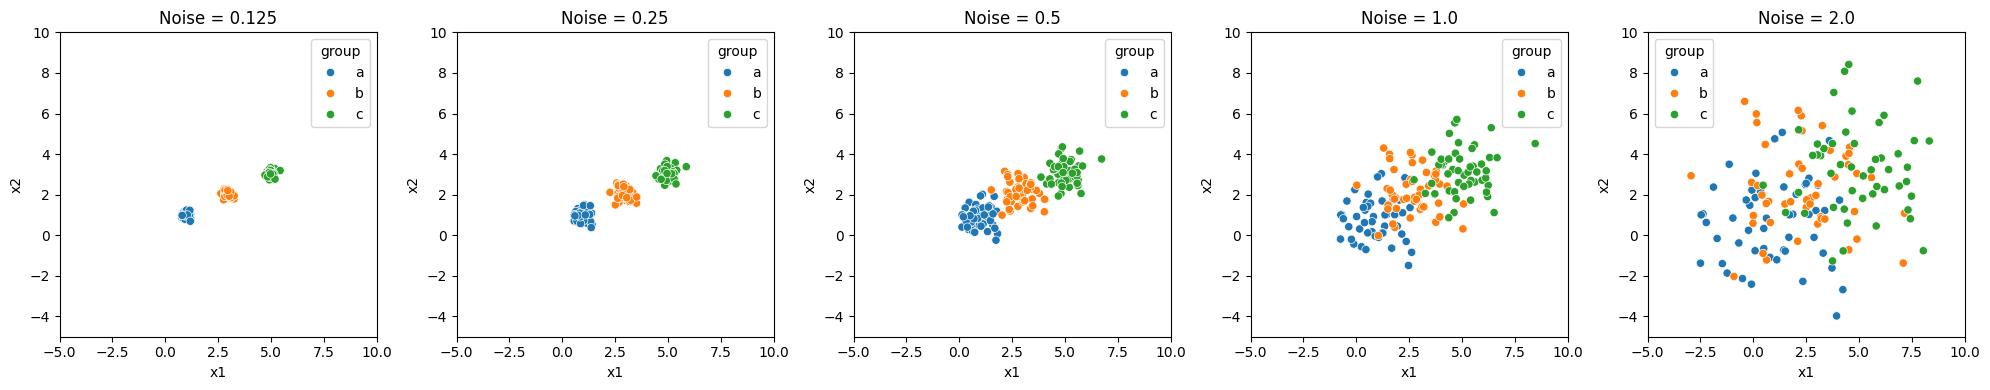

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

datasets = {
    "Noise = 0.125": df0_125,
    "Noise = 0.25": df0_25,
    "Noise = 0.5": df0_5,
    "Noise = 1.0": df1_0,
    "Noise = 2.0": df2_0
}

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, (name, df) in zip(axes, datasets.items()):
    sns.scatterplot(
        data=df,
        x="x1",
        y="x2",
        hue="group",
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlim(-5, 10)
    ax.set_ylim(-5, 10)

plt.tight_layout()
plt.show()


q1. part 2
As the noise increases from 0.125 to 2.0, the clusters become less visually distinct. At lower noise levels, the points are grouped closely together and are easy to separate. At higher noise levels, the points spread out and overlap, making it harder to identify the three clusters.

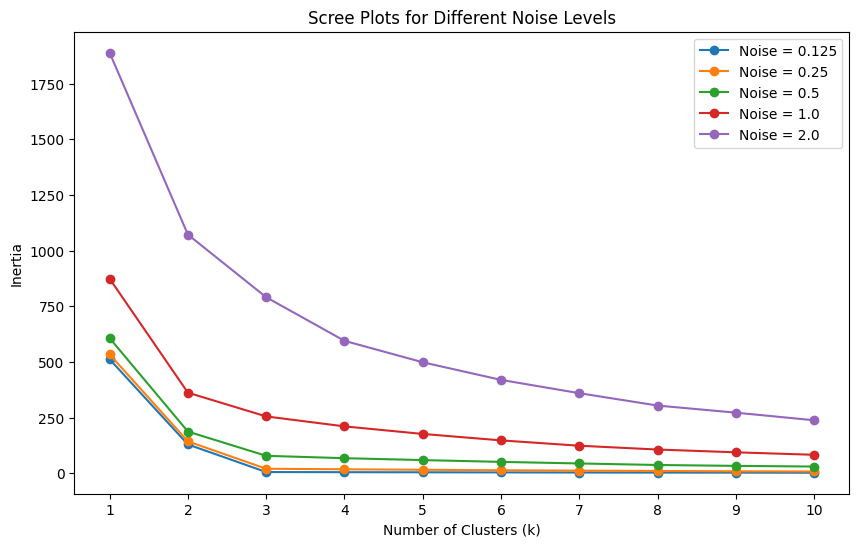

In [8]:

from sklearn.cluster import KMeans

plt.figure(figsize=(10, 6))

for name, df in datasets.items():

    X = df[["x1", "x2"]]

    inertia = []

    for k in range(1, 11):
        model = KMeans(
            n_clusters=k,
            random_state=100,
            n_init=10
        )

        model.fit(X)
        inertia.append(model.inertia_)

    plt.plot(
        range(1, 11),
        inertia,
        marker="o",
        label=name
    )

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Scree Plots for Different Noise Levels")
plt.legend()
plt.xticks(range(1, 11))
plt.show()


q1 part 3
As the noise increases, the scree plots generally show higher inertia and a less obvious elbow. At lower noise levels, the elbow is clearer around k = 3 because the clusters are well separated. At higher noise levels, the elbow becomes harder to identify because the clusters overlap, making it more difficult to confidently choose the best k.

q1 part 4
The elbow represents the point where adding more clusters no longer significantly reduces inertia. In this simulation, the data were created using three groups, so k = 3 is a reasonable choice when the noise is low. After k = 3, the improvement in inertia becomes smaller. As noise increases, the elbow becomes less clear because the groups overlap, making it harder to determine the optimal number of clusters.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

In [9]:


import pandas as pd

df = pd.read_csv("SIPRI Military Expenditure Database.csv")

df.head()



,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
0,0,1988,Afghanistan,NaN,NaN,NaN,NaN
1,1,1989,Afghanistan,NaN,NaN,NaN,NaN
2,2,1990,Afghanistan,NaN,NaN,NaN,NaN
3,3,1991,Afghanistan,NaN,NaN,NaN,NaN
4,4,1992,Afghanistan,NaN,NaN,NaN,NaN


In [10]:

# Select only the year 2020
df2020 = df[df["Year"] == 2020].copy()

# Remove rows with missing values
df2020 = df2020.dropna()

# Check the number of countries
print("Number of countries:", len(df2020))

# View the data
df2020.head()


Number of countries: 148


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


In [11]:

df2020.info()
df2020.describe()


<class 'pandas.core.frame.DataFrame'>
Index: 148 entries, 32 to 5880
Data columns (total 7 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   index                           148 non-null    int64  
 1   Year                            148 non-null    int64  
 2   Country                         148 non-null    object 
 3   Spending (2020 USD)             148 non-null    float64
 4   Percent of GDP                  148 non-null    float64
 5   Percent of Government Spending  148 non-null    float64
 6   Spending per Capita             148 non-null    float64
dtypes: float64(4), int64(2), object(1)
memory usage: 9.2+ KB


,index,Year,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
count,148.000000,148.0,148.000000,148.000000,148.000000,148.000000
mean,2831.256757,2020.0,13153.747670,0.019619,0.061510,268.264494
std,1654.299355,0.0,68005.236120,0.015033,0.046207,430.434878
min,32.000000,2020.0,8.622460,0.000054,0.004896,0.580129
25%,1409.000000,2020.0,204.877177,0.010413,0.031352,20.553464
50%,2871.000000,2020.0,959.535443,0.015324,0.047402,81.506703
75%,4222.500000,2020.0,5289.998320,0.024327,0.084681,326.267753
max,5880.000000,2020.0,778397.200000,0.098470,0.303027,2520.398541


q2 part 1
After filtering the dataset to 2020 and removing missing values, 148 countries remained. No further cleaning was necessary because all four spending variables were already numeric and had no missing values. The index and year columns are not needed for clustering.

In [12]:

from sklearn.preprocessing import MinMaxScaler

# Select the two variables
X = df2020[["Spending (2020 USD)", "Spending per Capita"]]

# Normalize the variables
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# View the normalized data
pd.DataFrame(X_scaled, columns=X.columns).head()


,Spending (2020 USD),Spending per Capita
0,0.000348,0.002620
1,0.000230,0.025615
2,0.012461,0.087630
3,0.001265,0.011767
4,0.003626,0.024627


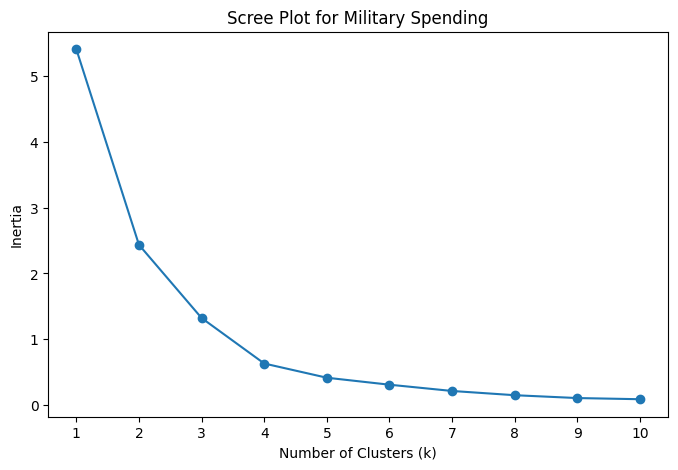

In [13]:

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=100,
        n_init=10
    )
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker="o")

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Scree Plot for Military Spending")
plt.xticks(range(1, 11))
plt.show()


q2 part 2:
Based on the scree plot, I chose k = 4 because the inertia decreases significantly up to four clusters and then begins to level off. Adding more clusters after k = 4 results in smaller improvements.

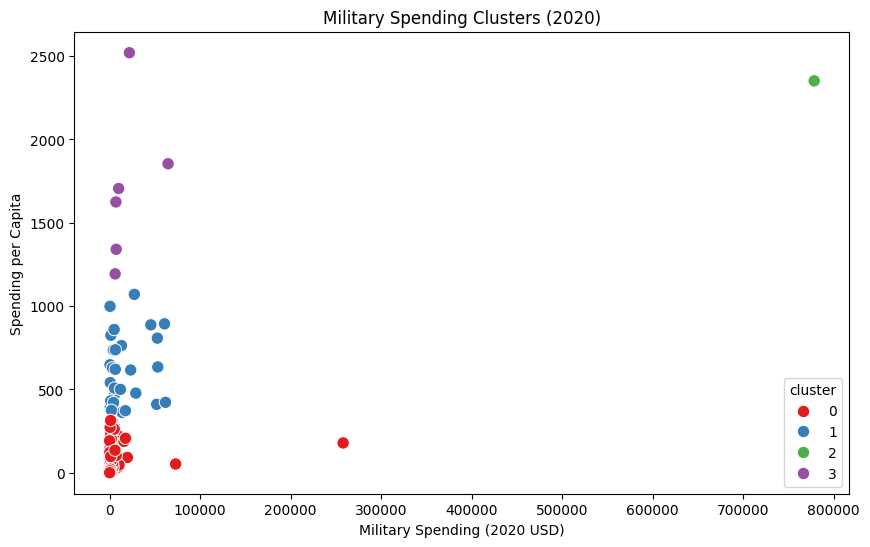

In [14]:

import seaborn as sns
from sklearn.cluster import KMeans

# Run K-means with 4 clusters
kmeans = KMeans(n_clusters=4, random_state=100, n_init=10)

# Assign each country to a cluster
df2020["cluster"] = kmeans.fit_predict(X_scaled)

# Create scatterplot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df2020,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster",
    palette="Set1",
    s=80
)

plt.title("Military Spending Clusters (2020)")
plt.xlabel("Military Spending (2020 USD)")
plt.ylabel("Spending per Capita")
plt.show()


---

In [15]:

df2020.groupby("cluster")[
    ["Spending (2020 USD)", "Spending per Capita"]
].describe()


Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                     111.0    4859.185065  25405.739131       8.622460   
1                      30.0   17077.591354  20583.053357     405.790494   
2                       1.0  778397.200000           NaN  778397.200000   
3                       6.0   19443.362047  22861.507114    6095.708713   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0           130.010211     382.464677    2297.032353  257973.429834   
1          2294.039665    5857.060906   26296.001003   61712.537169   
2        778397.200000  778397.200000  778397.200000  778397.200000   
3          7023.251766    8624.225729   18857.070183   64558.400000   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                     111.0    80.061470   83.501824     0.580129   
1                      30.0   607.478618  206.928757   362.467076   
2                       1.0  2351.631858         NaN  2351.631858   
3                       6.0  1706.721916  466.375705  1193.598730   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0          14.880549    47.056944   125.387558   314.201312  
1         422.208252   579.004604   757.328513  1070.623322  
2        2351.631858  2351.631858  2351.631858  2351.631858  
3        1412.083201  1665.447478  1817.219993  2520.398541

In [16]:

df2020[df2020["Country"] == "United States"]


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,cluster


In [17]:

df2020[df2020["Country"].str.contains("United", case=False, na=False)]


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,cluster
5506,5506,2020,United Kingdom,60675.039625,0.022408,0.045629,893.778388,1
5540,5540,2020,United States of America,778397.200000,0.037179,0.081976,2351.631858,2


In [18]:

df2020[df2020["cluster"] == 2][
    ["Country", "Spending (2020 USD)", "Spending per Capita"]
]


,Country,Spending (2020 USD),Spending per Capita
5540,United States of America,778397.2,2351.631858


Based on the scree plot, I selected k = 4. Most countries were grouped into Cluster 0, which had relatively low military spending and spending per capita. Cluster 1 contained countries with higher spending per capita, while Cluster 3 included countries with particularly high spending per capita. Cluster 2 contained only one country with extremely high total military spending, likely the United States. Overall, the clustering shows that military spending varies significantly across countries, with a few countries spending much more than the majority.

In [21]:

df2020[df2020["cluster"] == 2][
    ["Country", "Spending (2020 USD)", "Spending per Capita"]
]


,Country,Spending (2020 USD),Spending per Capita
5540,United States of America,778397.2,2351.631858


**Declaration:** I completed this version without generative AI.

**Student(s):** Eyram Golo

**Date:** 10/13/2026

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [20]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]